# Representation Demo

Walkthrough of the Representation component: primitives, `FloorPlanGraph` construction and mutation, physical constraints, the `Building`/`Storey` containers, and visualisation utilities.

See `docs/representation.md` for the full component specification.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from representation import constraints
from representation import visualisation as viz
from representation.building import Building
from representation.floor_plan import FloorPlanGraph
from representation.primitives import Junction, WallSegment

## Primitives

`Junction` and `WallSegment` are the atomic building blocks. A `WallSegment` references junction IDs rather than raw coordinates -- its geometry is always resolved from the current junction positions.

In [2]:
junction = Junction(id=0, position=(1.5, 2.0))
print(junction)
print("x:", junction.x, " y:", junction.y)

Junction(id=0, position=Array([1.5, 2. ], dtype=float32))
x: 1.5  y: 2.0


In [3]:
junctions = {0: junction, 1: Junction(id=1, position=(4.0, 2.0))}
wall = WallSegment(id=0, junction_start=0, junction_end=1)

print("segment geometry (x1, y1, x2, y2):", wall.as_array(junctions))
print("segment length:", wall.length(junctions))

segment geometry (x1, y1, x2, y2): [1.5 2.  4.  2. ]
segment length: 2.5


## Building a FloorPlanGraph

A `FloorPlanGraph` is a planar graph of junctions and wall segments. Rooms are not stored explicitly -- they emerge as cycles. Below we build a 4m x 2m footprint split into two rooms by an interior wall.

In [4]:
def build_two_room_floor_plan() -> FloorPlanGraph:
    graph = FloorPlanGraph()
    positions = [(0.0, 0.0), (2.0, 0.0), (4.0, 0.0), (4.0, 2.0), (2.0, 2.0), (0.0, 2.0)]
    j = [graph.add_junction(p) for p in positions]

    perimeter_pairs = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]
    for start, end in perimeter_pairs:
        graph.add_segment(j[start].id, j[end].id)

    graph.add_segment(j[1].id, j[4].id)  # dividing wall between the two rooms
    return graph


floor_plan = build_two_room_floor_plan()
print(f"{len(floor_plan.junctions)} junctions, {len(floor_plan.segments)} segments")

6 junctions, 7 segments


In [5]:
print("segment array shape:", floor_plan.to_segment_array().shape)
print("junction array shape:", floor_plan.to_junction_array().shape)
print("valid segment rows:", int(floor_plan.segment_mask().sum()))
print("valid junction rows:", int(floor_plan.junction_mask().sum()))

rooms = floor_plan.cycles()
print(f"\nfound {len(rooms)} rooms (cycles):")
for room in rooms:
    print(" ", room)

print("\nconnected:", floor_plan.is_connected())
print("planar:", floor_plan.is_planar())
print("valid:", floor_plan.is_valid())

segment array shape: (128, 4)
junction array shape: (256, 2)
valid segment rows: 7
valid junction rows: 6

found 2 rooms (cycles):
  [4, 1, 0, 5]
  [4, 3, 2, 1]

connected: True
planar: True
valid: True


## Mutating the graph

Moving a junction implicitly moves every incident wall segment. Merging and splitting junctions are the dimensionality-reducing / dimensionality-increasing moves RJMCMC needs.

In [6]:
original_position = floor_plan.junctions[4].position
floor_plan.move_junction(4, (2.0, 2.5))
print("moved junction 4:", original_position, "->", floor_plan.junctions[4].position)

floor_plan.move_junction(4, original_position)  # restore for later cells
print("restored junction 4:", floor_plan.junctions[4].position)

moved junction 4: [2. 2.] -> [2.  2.5]
restored junction 4: [2. 2.]


In [7]:
# merge_junctions: collapse two nearby junctions (e.g. from an RJMCMC birth proposal) into one
merge_demo = FloorPlanGraph()
a = merge_demo.add_junction((0.0, 0.0))
b = merge_demo.add_junction((0.08, 0.0))
c = merge_demo.add_junction((1.0, 0.0))
merge_demo.add_segment(a.id, c.id)
merge_demo.add_segment(b.id, c.id)

print("junctions before merge:", list(merge_demo.junctions))
merged = merge_demo.merge_junctions(a.id, b.id)
print("junctions after merge: ", list(merge_demo.junctions))
print("merged junction", merged.id, "at", merged.position)

junctions before merge: [0, 1, 2]
junctions after merge:  [0, 2]
merged junction 0 at [0.04 0.  ]


In [8]:
# split_junction: the inverse move -- turn one junction into two along a direction
split_demo = FloorPlanGraph()
origin = split_demo.add_junction((1.0, 1.0))
north = split_demo.add_junction((1.0, 2.0))
east = split_demo.add_junction((2.0, 1.0))
west = split_demo.add_junction((0.0, 1.0))
split_demo.add_segment(origin.id, north.id)
split_demo.add_segment(origin.id, east.id)
split_demo.add_segment(origin.id, west.id)

junction_a, junction_b = split_demo.split_junction(origin.id, direction=(1.0, 0.0))
print("split into", junction_a.id, "at", junction_a.position, "and", junction_b.id, "at", junction_b.position)
print("segments after split:", list(split_demo.segments))

split into 4 at [1.05 1.  ] and 5 at [0.95 1.  ]
segments after split: [0, 1, 2, 3]


## Constraints

Every physical constraint is exposed both as a soft penalty (zero when satisfied) and a hard validator (raises `ConstraintViolation`).

In [9]:
print("planarity penalty:", constraints.planarity_penalty(floor_plan))
print("length penalty:  ", constraints.length_penalty(floor_plan))
print("valence penalty: ", constraints.valence_penalty(floor_plan))
print("bounds penalty:  ", constraints.bounds_penalty(floor_plan, (0.0, 0.0, 4.0, 2.0)))

constraints.validate_all(floor_plan, bounds=(0.0, 0.0, 4.0, 2.0))
print("\nfloor_plan passes validate_all")

planarity penalty: 0.0
length penalty:   0.0
valence penalty:  0.0
bounds penalty:   0.0

floor_plan passes validate_all


In [10]:
# a dangling wall: both endpoints have valence 1, violating the min-valence constraint
broken = FloorPlanGraph()
p = broken.add_junction((0.0, 0.0))
q = broken.add_junction((1.0, 0.0))
broken.add_segment(p.id, q.id)

print("valence penalty:", constraints.valence_penalty(broken))
try:
    constraints.validate_all(broken)
except constraints.ConstraintViolation as exc:
    print("validation failed as expected:", exc)

valence penalty: 2.0
validation failed as expected: Junctions [0, 1] have fewer than 2 incident segments


## Building and Storey containers

A `Building` is an ordered stack of `Storey` objects, each holding its own `FloorPlanGraph` and height range.

In [11]:
building = Building()

ground_floor = building.add_storey(z_min=0.0, z_max=3.0)
ground_floor.floor_plan = build_two_room_floor_plan()

first_floor = building.add_storey(z_min=3.0, z_max=6.0)
first_floor.floor_plan = build_two_room_floor_plan()
first_floor.floor_plan.move_junction(4, (2.0, 2.5))  # vary the layout slightly

print(f"building has {len(building.storeys)} storeys")
for storey in building.storeys:
    print(f"  z in [{storey.z_min}, {storey.z_max}]: {len(storey.floor_plan.segments)} segments")

building has 2 storeys
  z in [0.0, 3.0]: 7 segments
  z in [3.0, 6.0]: 7 segments


## Visualisation

`plot_floor_plan` draws segments as lines, junctions as points, and rooms as shaded polygons.

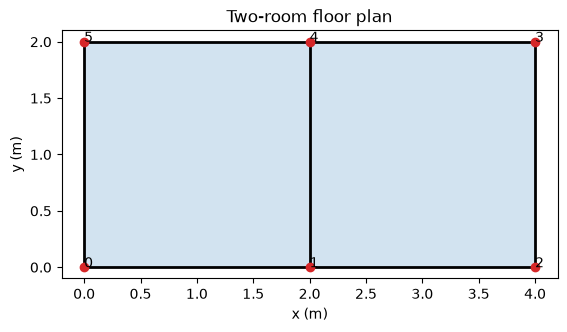

In [12]:
ax = viz.plot_floor_plan(floor_plan, show_junction_ids=True)
ax.set_title("Two-room floor plan")
plt.show()

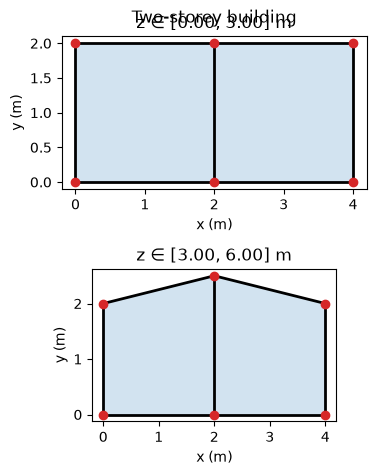

In [13]:
fig = building.plot()
fig.suptitle("Two-storey building")
plt.show()

`plot_point_cloud_overlay` overlays 2D scan points on a floor plan -- useful once the Simulator produces real `FloorPointCloud` slices. Here we stand in a synthetic scatter sampled along each wall.

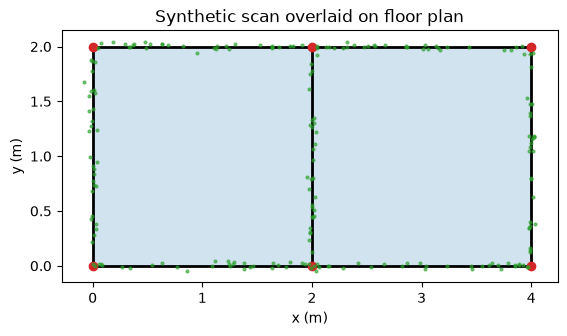

In [14]:
rng = np.random.default_rng(0)


def sample_points_along_segments(graph, n_per_segment=30, noise_sigma=0.02):
    points = []
    for segment in graph.segments.values():
        start = np.array(graph.junctions[segment.junction_start].position)
        end = np.array(graph.junctions[segment.junction_end].position)
        t = rng.uniform(0.0, 1.0, size=n_per_segment)
        segment_points = start + t[:, None] * (end - start)
        segment_points += rng.normal(scale=noise_sigma, size=segment_points.shape)
        points.append(segment_points)
    return np.concatenate(points, axis=0)


synthetic_scan = sample_points_along_segments(floor_plan)
ax = viz.plot_point_cloud_overlay(floor_plan, synthetic_scan)
ax.set_title("Synthetic scan overlaid on floor plan")
plt.show()

This exercises the full Representation component: primitives, `FloorPlanGraph` construction/mutation/queries, constraints, containers, and visualisation. Next: `02_simulator_demo.ipynb`.